# Week4_ex2_analysis — Generator Mvar limits: `enforce_q_lims` against PowerWorld's back-off (deep dive)

The 37-bus case of Examples 6.13–6.15 (Glover, Overbye & Sarma, *Power System Analysis and Design*, 7th ed.) has two voltage-controlling units, PEAR138 and PEAR69, tied by a 1:1 transformer with different setpoints (1.02 and 1.01 pu). They fight over the reactive power between them, and how the solver treats a unit that hits its Mvar limit decides which operating point comes out.

A unit with Mvar limits has three valid states, and its voltage must sit on the side its limit explains:

$$
Q_{\min} < Q_i < Q_{\max} \;\Rightarrow\; V_i = V_i^{set}, \qquad
Q_i = Q_{\max} \;\Rightarrow\; V_i \le V_i^{set}, \qquad
Q_i = Q_{\min} \;\Rightarrow\; V_i \ge V_i^{set}
$$

A unit parked at $Q_{\min}$ (absorbing as hard as it can) while its bus sits below setpoint would, in reality, stop absorbing. pandapower's `enforce_q_lims=True` turns a PV bus into PQ when its limit is exceeded but never checks this condition again; PowerWorld does (`Check Back Off Immediately`). This notebook measures what that difference does to one solved case and to a full N-1 scan.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pandapower as pp

# 1. Case data, PowerWorld reference results and the shared solver are in case37.py next to this notebook
from case37 import (BUSES, GENS, TRAFOS, SLACK_BUS, PW, PW_CA, build_case, set_status, set_tap, solve_pw,
                    gen_q, amp_loading)

IMG = Path("Images")
IMG.mkdir(exist_ok=True)

In [2]:
# 2. The two ways of handling Mvar limits. H1 is pandapower's built-in switch, H2 adds the back-off check
def solve_h1(net):
    net.gen["in_service"] = net.gen.pv_on
    pp.runpp(net, enforce_q_lims=True, trafo_model="pi")
    net["parked"] = {}
    return net


def unit_table(net, method):
    q = gen_q(net) if method == "H2" else net.res_gen.q_mvar
    out = []
    for i in net.gen.index[net.gen.pv_on.astype(bool)]:
        b = net.gen.at[i, "bus"]
        out.append({"Unit": net.gen.at[i, "name"], "Method": method, "Q [Mvar]": q[i],
                    "Q min [Mvar]": net.gen.at[i, "min_q_mvar"], "Q max [Mvar]": net.gen.at[i, "max_q_mvar"],
                    "V [pu]": net.res_bus.vm_pu[b], "V set [pu]": net.gen.at[i, "vm_pu"]})
    return pd.DataFrame(out)


h1 = solve_h1(build_case())
h2 = solve_pw(build_case())
pw_q = {f"G{bus}-{gid}": PW["ex6_13"]["gen_q"][k] for k, (bus, gid, on, *_ ) in enumerate(GENS) if on and bus != SLACK_BUS}
units = pd.concat([unit_table(h1, "H1"), unit_table(h2, "H2")])
units["Q PowerWorld [Mvar]"] = units.Unit.map(pw_q)
units[units.Unit.isin(["G44-1", "G53-1", "G54-1"])].round(4)

,Unit,Method,Q [Mvar],Q min [Mvar],Q max [Mvar],V [pu],V set [pu],Q PowerWorld [Mvar]
2,G44-1,H1,40.0000,-20.0,40.0,1.0190,1.02,29.6814
4,G53-1,H1,45.0000,0.0,45.0,0.9943,1.02,45.0000
5,G54-1,H1,-20.0000,-20.0,60.0,0.9997,1.01,7.6786
2,G44-1,H2,29.6528,-20.0,40.0,1.0200,1.02,29.6814
4,G53-1,H2,45.0000,0.0,45.0,1.0015,1.02,45.0000
5,G54-1,H2,7.6565,-20.0,60.0,1.0100,1.01,7.6786


In [3]:
# 3. Theory vs measurement: check every unit against the three valid states
def state_check(table, tol_q=1e-3, tol_v=5e-5):
    rows = []
    for _, r in table.iterrows():
        at_max = r["Q [Mvar]"] >= r["Q max [Mvar]"] - tol_q
        at_min = r["Q [Mvar]"] <= r["Q min [Mvar]"] + tol_q
        if at_max:
            state, valid = "at Q max", r["V [pu]"] <= r["V set [pu]"] + tol_v
        elif at_min:
            state, valid = "at Q min", r["V [pu]"] >= r["V set [pu]"] - tol_v
        else:
            state, valid = "regulating", abs(r["V [pu]"] - r["V set [pu]"]) <= tol_v
        rows.append({"Method": r.Method, "Unit": r.Unit, "State": state,
                     "V - V set [pu]": r["V [pu]"] - r["V set [pu]"], "Valid": valid})
    return pd.DataFrame(rows)


check = state_check(units)
dv = {m: (n.res_bus.vm_pu - pd.Series(PW["ex6_13"]["vm"], index=[b for b, _, _ in BUSES])).abs().max() for m, n in (("H1", h1), ("H2", h2))}
display(pd.DataFrame({"Method": ["H1", "H2"], "Invalid units": [int((~check.Valid[check.Method == m]).sum()) for m in ("H1", "H2")],
                      "Max |V - V_PW| [pu]": [dv["H1"], dv["H2"]]}))
check[check.Unit.isin(["G53-1", "G54-1"])].round(5)

,Method,Invalid units,Max |V - V_PW| [pu]
0,H1,1,0.010299
1,H2,0,0.000007


,Method,Unit,State,V - V set [pu],Valid
4,H1,G53-1,at Q max,-0.02566,True
5,H1,G54-1,at Q min,-0.01030,False
10,H2,G53-1,at Q max,-0.01854,True
11,H2,G54-1,regulating,0.00000,True


## Hypothesis 1

pandapower's `enforce_q_lims=True` reaches the same operating point as PowerWorld on the saved cases (Examples 6.13, 6.13 with OAK69–WALNUT69 open, 6.15, Problems 6.52 and 6.53). If it does, the limit handling needs no extra code.

In [4]:
# 4. Five saved cases, both methods, against the PowerWorld bus voltages and angles
def case_net(key):
    case = {"ex6_13": "6_13", "ex6_13_open": "6_13", "ex6_15": "6_15", "p6_52": "6_52", "p6_53": "6_53"}[key]
    net = build_case(case)
    if key == "ex6_13_open":
        set_status(net, "12-18-1", False)
    for k, (f, t, ckt, *_ ) in enumerate(TRAFOS):
        set_tap(net, f"{f}-{t}-{ckt}", PW[key]["taps"][k])
    return net


rows = []
for key in ["ex6_13", "ex6_13_open", "ex6_15", "p6_52", "p6_53"]:
    ref_v = pd.Series(PW[key]["vm"], index=[b for b, _, _ in BUSES])
    ref_a = pd.Series(PW[key]["va"], index=[b for b, _, _ in BUSES])
    for method, solver in (("H1", solve_h1), ("H2", solve_pw)):
        net = solver(case_net(key))
        invalid = int((~state_check(unit_table(net, method)).Valid).sum())
        rows.append({"Case": key, "Method": method,
                     "Max |V - V_PW| [pu]": (net.res_bus.vm_pu - ref_v).abs().max(),
                     "Max |delta - delta_PW| [deg]": (net.res_bus.va_degree - ref_a).abs().max(),
                     "Slack P [MW]": net.res_ext_grid.p_mw.iloc[0], "Invalid units": invalid})
cases = pd.DataFrame(rows)
cases[cases.Method == "H1"].round(5)

,Case,Method,Max |V - V_PW| [pu],Max |delta - delta_PW| [deg],Slack P [MW],Invalid units
0,ex6_13,H1,0.01030,0.11820,217.92210,1
2,ex6_13_open,H1,0.01713,0.28836,224.39806,1
4,ex6_15,H1,0.01328,0.16803,220.27461,1
6,p6_52,H1,0.01064,0.12607,217.92217,1
8,p6_53,H1,0.01058,0.12329,217.85263,1


In every case H1 settles with PEAR69 parked at its $-20$ Mvar limit while its bus sits about 0.01 pu **below** its setpoint, the state the second condition rules out. With PEAR69 absorbing 20 Mvar it should not be absorbing, the whole system is pulled down: 0.010 to 0.017 pu lower voltages and 0.12° to 0.29° in angle across the five cases, with no error or warning.

**Verdict: rejected.**

## Hypothesis 2

Adding PowerWorld's back-off check (a parked unit returns to voltage control as soon as its bus crosses the setpoint on the wrong side) reproduces PowerWorld on the same five cases, to within the single-precision resolution of the case files.

In [5]:
# 5. Same five cases with the back-off loop
cases[cases.Method == "H2"].round(6)

,Case,Method,Max |V - V_PW| [pu],Max |delta - delta_PW| [deg],Slack P [MW],Invalid units
1,ex6_13,H2,0.000007,0.000073,217.640353,0
3,ex6_13_open,H2,0.000014,0.000179,223.811976,0
5,ex6_15,H2,0.000008,0.000124,219.961977,0
7,p6_52,H2,0.000007,0.000050,217.635948,0
9,p6_53,H2,0.000006,0.000073,217.565032,0


All five cases match to about $10^{-5}$ pu and $10^{-4}$ degrees, and no unit is left in an invalid state. The remaining difference is the 0.1 MVA convergence tolerance of the PowerWorld solution.

**Verdict: accepted.**

## Hypothesis 3

The H1 error is large enough to change a planning verdict: a full N-1 scan (43 lines and 14 transformers, taps and switched shunts frozen) run with H1 reports violations that PowerWorld's contingency analysis does not.

In [6]:
# 6. N-1 with both methods, judged with PowerWorld's limits (current at nominal voltage > 100%, bus voltage < 0.95 pu)
def scan(solver):
    names = list(build_case().line.name) + list(build_case().trafo.name)
    out, minv = [], {}
    for name in names:
        net = build_case()
        set_status(net, name, False)
        solver(net)
        load = amp_loading(net)
        v = net.res_bus.vm_pu
        minv[name] = v.min()
        out += [(name, f"branch {el}") for el in load[load > 100].index]
        out += [(name, f"bus {b}") for b in v[v < 0.95].index]
    return set(out), pd.Series(minv)


def ca_key(ctg, element):
    a, b = re.match(r"[LT]_(\d{6})[^-]*-(\d{6})", ctg).groups()
    ckt = ctg.rsplit("C", 1)[1]
    names = list(build_case().line.name) + list(build_case().trafo.name)
    outage = next(n for n in (f"{int(a)}-{int(b)}-{ckt}", f"{int(b)}-{int(a)}-{ckt}") if n in names)
    tok = element.split()
    return (outage, f"bus {tok[1]}") if tok[0] == "VLOW" else (outage, f"branch {tok[1]}-{tok[2]}-{tok[3]}")


pw_set = {ca_key(c[0], c[1]) for c in PW_CA}
h1_set, h1_minv = scan(solve_h1)
h2_set, h2_minv = scan(solve_pw)
assert h2_set == pw_set
display(pd.DataFrame({
    "Method": ["PowerWorld CA", "H1 enforce_q_lims", "H2 back-off"],
    "Violations": [len(pw_set), len(h1_set), len(h2_set)],
    "Contingencies with a violation": [len({o for o, _ in s}) for s in (pw_set, h1_set, h2_set)],
    "False alarms": [0, len(h1_set - pw_set), len(h2_set - pw_set)],
    "Missed": [0, len(pw_set - h1_set), len(pw_set - h2_set)],
}))
pd.DataFrame(sorted(h1_set - pw_set), columns=["Outage", "Reported only by H1"])

,Method,Violations,Contingencies with a violation,False alarms,Missed
0,PowerWorld CA,8,4,0,0
1,H1 enforce_q_lims,13,4,5,0
2,H2 back-off,8,4,0,0


,Outage,Reported only by H1
0,10-13-1,bus 55
1,10-39-1,bus 10
2,10-39-1,bus 13
3,10-39-1,bus 55
4,12-18-1,bus 5


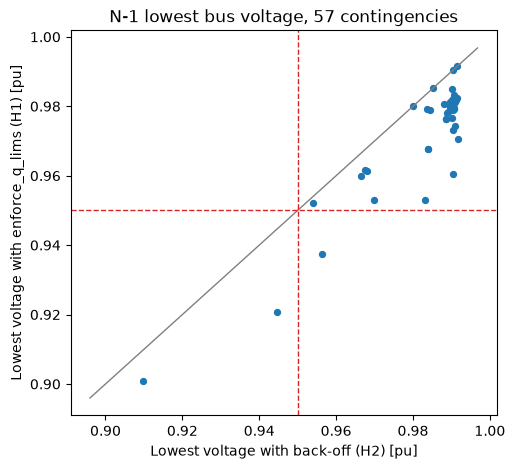

,Quantity,Value
0,Contingencies where H1 is lower,53.0000
1,Contingencies where H1 is higher,0.0000
2,Largest underestimate [pu],0.0301
3,Median underestimate [pu],0.0089


In [7]:
# 7. Lowest bus voltage of every contingency, H1 against H2
gap = (h2_minv - h1_minv)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(h2_minv, h1_minv, s=18)
lim = [min(h1_minv.min(), h2_minv.min()) - 0.005, max(h1_minv.max(), h2_minv.max()) + 0.005]
ax.plot(lim, lim, color="gray", lw=1)
ax.axhline(0.95, color="tab:red", ls="--", lw=1)
ax.axvline(0.95, color="tab:red", ls="--", lw=1)
ax.set_xlabel("Lowest voltage with back-off (H2) [pu]")
ax.set_ylabel("Lowest voltage with enforce_q_lims (H1) [pu]")
ax.set_title("N-1 lowest bus voltage, 57 contingencies")
fig.savefig(IMG / "Week4_ex2_analysis_qlimit_n1_min_voltage.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({"Quantity": ["Contingencies where H1 is lower", "Contingencies where H1 is higher",
                           "Largest underestimate [pu]", "Median underestimate [pu]"],
              "Value": [int((gap > 1e-4).sum()), int((gap < -1e-4).sum()), gap.max(), gap.median()]}).round(4)

Every point sits on or below the diagonal: H1 never reports a higher voltage than H2. It is lower in 53 of the 57 contingencies, by 0.009 pu at the median and 0.030 pu at worst, which pushes five more buses under 0.95 pu. All five extra alarms fall inside the four contingencies PowerWorld already flags, and nothing is missed, so the error is one-sided and conservative; it still inflates the list of buses that would need voltage support.

**Verdict: accepted.**

## Final conclusion

`enforce_q_lims=True` is necessary (without it a unit supplies unlimited Mvar) but not sufficient. When two voltage-controlling units are electrically close, pandapower can park one of them on a limit it should leave, and the solution converges quietly at voltages about 0.01 pu low in the base case and up to 0.03 pu low after a contingency. In this system that turned 8 genuine N-1 violations into 13.

For the Projects pipeline this changes the solver, not just a tolerance:

- Every power flow in the time-series and N-1 sweeps goes through a back-off loop like `solve_pw`: switch PV to PQ at the limit, and switch back once the voltage moves to the side the limit no longer explains.
- After each solve, check the three-state condition above and log any unit that breaks it; a nonzero count means the result is not a valid operating point.
- Report N-1 results with control state stated (here: taps and switched shunts frozen), since that is the condition under which pandapower and PowerWorld agree exactly.